# Import Libraries

In [6]:
import pandas as pd
import numpy as np
import collections

# Import DataFrame

In [9]:
df_filepath = "merged_embeddings_sampled.pkl"

df = pd.read_pickle(df_filepath).reset_index(drop=True)

# EDA

Split dataset into train and test

In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()

target_column = 'Party_orientation'
sentence_column = 'lemmas'
y = df[target_column]
X_lemmas = df[sentence_column]

TEST_SIZE = 0.1
RANDOM_STATE = 42

X_train_lemmas, X_test_lemmas, y_train, y_test = train_test_split(X_lemmas, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

Let us check whether we have class imbalance.

Party_orientation
Right    0.621028
Left     0.378972
Name: proportion, dtype: float64


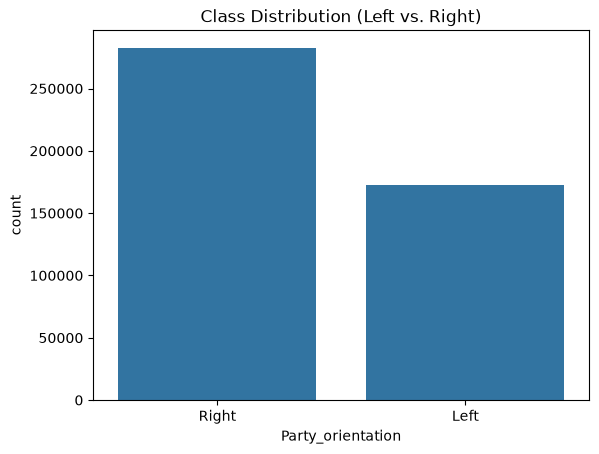

In [27]:
import seaborn as sns

g = sns.countplot(x=y_train) # Plotting class counts
g.set_title("Class Distribution (Left vs. Right)")

class_proportions = y_train.value_counts(normalize=True)
print(class_proportions) # Printing class probabilities

We can see we have a mild imbalance, with a skew towards the right.

For a 1D CNN, we need word-level representations. Therefore this implementation will focus on token indicators.

Since our CNN will take input at the word-level, we need to explicitly define a cutoff for the max length of the sentence. If input sentences are longer than this, they will be truncated to this max length. If shorter, it will be padded to this length using an explicit \<PAD> token.

Let's determine the max length empirically.

In [40]:
LENGTH_PERCENTILE = 0.95 # 95th percentile of sentence length
max_length = int(np.ceil(X_train_lemmas.apply(len).quantile(0.95)))

print(f"Max length: {max_length}")

Max length: 61


To conclude our EDA, we will use a 1D CNN with token indicators. We will use a max length of 61 and we will attempt to address the mild class imbalance.

Label Encoding Targets

In [42]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

Computing Class Weights

In [61]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights

array([1.31935847, 0.80511676])

Inspecting Index -> Class -> Weight Mapping

In [63]:
for idx, class_name in enumerate(le.classes_):
    print(f"Index {idx} -> {class_name} -> Weight: {class_weights[idx]:.4f}")

Index 0 -> Left -> Weight: 1.3194
Index 1 -> Right -> Weight: 0.8051


In this step we will transform our dataset of lemmas into a sequence of integers. Since we have way too many unique lemmas, we will derive our vocabulary size empirically as well.

We will make use of two extra tokens \<PAD> and \<UNK>:

1. The pad token will be used to ensure all our sentences have our empirically calculated max length. 

2. Our sequence encoder will take as input a frequency threshold. This determines the percentile of frequencies we would like our vocabulary to capture. We will group all lemmas not in our vocab into the unknown token.

In [65]:
class SequenceEncoder():
    def __init__(self, freq_threshold=0.8, max_length=50):
        self.freq_threshold = freq_threshold
        self.word_to_id = {}
        self.vocab = []
        self.vocab_size = 0
        self.pad_id = 0
        self.unk_id = None
        self.max_length = max_length

    def _calculate_threshold(self, token_frequencies):
        counts = np.array([count for _, count in token_frequencies.most_common()], dtype=np.uint64)
        cumulative_counts = np.cumsum(counts)
        normalized_cumulative_counts = cumulative_counts / cumulative_counts[-1]

        return int(np.searchsorted(normalized_cumulative_counts, self.freq_threshold) + 1)

    def fit(self, sentences):
        token_frequencies = collections.Counter()
        for sentence in sentences:
            token_frequencies.update(sentence)

        threshold = self._calculate_threshold(token_frequencies)
        top_lemmas_with_count = token_frequencies.most_common(threshold)

        self.vocab = [lemma for lemma, _ in top_lemmas_with_count]
        self.vocab_size = len(self.vocab) + 2 # 1 for <UNK> and 1 for <PAD>
        self.unk_id = self.vocab_size - 1

        self.word_to_id = {word: idx for idx, word in enumerate(self.vocab, start=1)}
        self.word_to_id['<PAD>'] = self.pad_id
        self.word_to_id['<UNK>'] = self.unk_id

        return self

    def transform(self, sentences):
        if not self.word_to_id:
            raise RuntimeError("SequenceEncoder must be fitted before calling transform().")

        num_samples = len(sentences)
        int_representations = np.zeros((num_samples, self.max_length), dtype=np.uint32)

        word_mapping = self.word_to_id
        unk_idx = self.unk_id
        max_len = self.max_length

        for i, sentence in enumerate(sentences):
            truncated = sentence[:max_len]
            for j, lemma in enumerate(truncated):
                int_representations[i, j] = word_mapping.get(lemma, unk_idx)

        return int_representations

    def fit_transform(self, sentences):
        return self.fit(sentences).transform(sentences)

In [66]:
encoder = SequenceEncoder(freq_threshold=0.8, max_length=max_length)
X_train_int = encoder.fit_transform(X_train_lemmas)
X_test_int = encoder.transform(X_test_lemmas)

print(f"Vocab size (including PAD & UNK): {encoder.vocab_size}")
print(f"X_train shape: {X_train_int.shape}")
print(f"X_test shape:  {X_test_int.shape}")

Vocab size (including PAD & UNK): 1128
X_train shape: (454833, 61)
X_test shape:  (50537, 61)


Let's now convert our dataset into tensors to work with PyTorch dataloaders.

In [71]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_int, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_int, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_tensor_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_tensor_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 128
train_loader = DataLoader(train_tensor_dataset, batch_size, shuffle=True)
test_loader = DataLoader(test_tensor_dataset, batch_size, shuffle=False)

Defining Model Architecture (Using an Embeddings Layer)

In [95]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class EmbeddingConvNet(nn.Module):
    def __init__(self, vocab_size, num_classes=2, embedding_dim=256, output_channels=64, kernel_size=3, dropout=0.3, padding_idx=0):
        super(EmbeddingConvNet, self).__init__()
        self.emb = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.conv1 = nn.Conv1d(embedding_dim, output_channels, kernel_size, padding='same')
        self.conv2 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.conv3 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.pool = nn.AdaptiveMaxPool1d(output_size=1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(output_channels, num_classes)

    def forward(self, x):
        x = self.emb(x) # (batch, max_length) -> (batch, max_length, vocab_size)
        x = x.permute(0, 2, 1) # (batch, max_length, vocab_size) -> (batch, vocab_size, max_length)

        x = self.conv1(x)
        x = F.relu(x)

        x = self.conv2(x)
        x = F.relu(x)

        x = self.conv3(x)
        x = F.relu(x)

        x = self.pool(x)


        x = x.squeeze(-1) # (batch, output_channels, 1) -> (batch, output_channels)

        x = self.dropout(x)

        x = self.fc1(x)

        return x

In [96]:
import torch.optim as optim

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = EmbeddingConvNet(vocab_size=encoder.vocab_size).to(device)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights.astype(np.float32)).to(device))
optimizer = optim.Adam(model.parameters(), lr=0.001)

Training model

In [93]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import f1_score
from tqdm.auto import tqdm


def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc="Train", leave=False)

    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        bs = y.size(0)
        total_loss += loss.item() * bs
        correct += (out.argmax(1) == y).sum().item()
        total += bs
        pbar.set_postfix(
            loss=f"{total_loss / total:.4f}", acc=f"{correct / total:.2%}"
        )

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds, targets = [], []
    pbar = tqdm(loader, desc="Val", leave=False)

    with torch.no_grad():
        for x, y in pbar:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)

            bs = y.size(0)
            pred = out.argmax(1)
            total_loss += loss.item() * bs
            correct += (pred == y).sum().item()
            total += bs

            preds.extend(pred.cpu().tolist())
            targets.extend(y.cpu().tolist())

    macro_f1 = f1_score(targets, preds, average="macro", zero_division=0)
    return total_loss / total, correct / total, macro_f1


def fit(
    model, train_loader, val_loader, criterion, optimizer, device, epochs=5
):
    history = []
    for epoch in range(1, epochs + 1):
        t_loss, t_acc = train_epoch(
            model, train_loader, criterion, optimizer, device
        )
        v_loss, v_acc, v_f1 = evaluate(model, val_loader, criterion, device)

        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {t_loss:.4f} - Acc: {t_acc:.2%} | "
            f"Val Loss: {v_loss:.4f} - Acc: {v_acc:.2%} - F1: {v_f1:.4f}"
        )

        history.append(
            {
                "epoch": epoch,
                "train_loss": t_loss,
                "val_loss": v_loss,
                "train_acc": t_acc,
                "val_acc": v_acc,
                "val_macro_f1": v_f1,
            }
        )

    return pd.DataFrame(history)


def plot_metrics(df):
    sns.set_theme(style="whitegrid")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    # Loss Curves
    sns.lineplot(
        data=df,
        x="epoch",
        y="train_loss",
        label="Train Loss",
        marker="o",
        ax=ax1,
    )
    sns.lineplot(
        data=df, x="epoch", y="val_loss", label="Val Loss", marker="o", ax=ax1
    )
    ax1.set_title("Cross-Entropy Loss", fontweight="bold")
    ax1.set_ylabel("Loss")

    # Metric Curves
    sns.lineplot(
        data=df,
        x="epoch",
        y="val_macro_f1",
        label="Val Macro F1",
        marker="o",
        ax=ax2,
    )
    sns.lineplot(
        data=df,
        x="epoch",
        y="val_acc",
        label="Val Accuracy",
        marker="s",
        ax=ax2,
    )
    ax2.set_title("Validation Macro F1 & Accuracy", fontweight="bold")
    ax2.set_ylabel("Score")
    ax2.set_ylim(0, 1.0)

    plt.tight_layout()
    plt.show()

Epoch 01/05 | Train Loss: 0.5526 - Acc: 69.96% | Val Loss: 0.6278 - Acc: 66.00% - F1: 0.6506


Epoch 02/05 | Train Loss: 0.5443 - Acc: 70.51% | Val Loss: 0.6259 - Acc: 65.11% - F1: 0.6443


Epoch 03/05 | Train Loss: 0.5368 - Acc: 71.12% | Val Loss: 0.6358 - Acc: 65.15% - F1: 0.6449


Epoch 04/05 | Train Loss: 0.5285 - Acc: 71.63% | Val Loss: 0.6409 - Acc: 64.53% - F1: 0.6402


Epoch 05/05 | Train Loss: 0.5211 - Acc: 71.99% | Val Loss: 0.6637 - Acc: 65.03% - F1: 0.6430


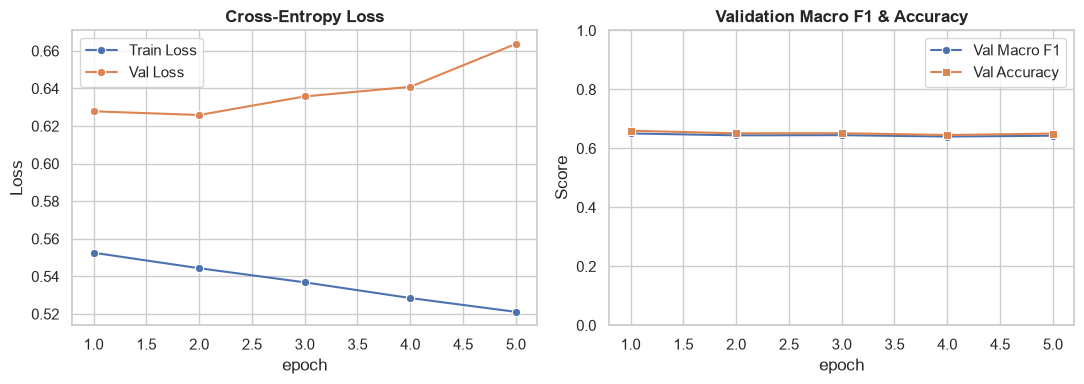

In [94]:
history_df = fit(
    model, train_loader, test_loader, criterion, optimizer, device, epochs=5
)
plot_metrics(history_df)

Hyperparameter Search with Optuna

In [97]:
import optuna


def objective(
    trial,
    vocab_size,
    train_loader,
    val_loader,
    criterion,
    device,
    epochs_per_trial=4,
):
    # 1. Hyperparameter search space
    embedding_dim = trial.suggest_categorical(
        "embedding_dim", [64, 128, 256]
    )
    output_channels = trial.suggest_categorical(
        "output_channels", [32, 64, 128]
    )
    kernel_size = trial.suggest_categorical("kernel_size", [3, 5])
    dropout = trial.suggest_float("dropout", 0.1, 0.5, step=0.1)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # 2. Instantiate model and optimizer
    model = EmbeddingConvNet(
        vocab_size=vocab_size,
        num_classes=2,
        embedding_dim=embedding_dim,
        output_channels=output_channels,
        kernel_size=kernel_size,
        dropout=dropout,
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )

    best_val_f1 = 0.0

    # 3. Training & Evaluation loop per trial
    for epoch in range(1, epochs_per_trial + 1):
        train_epoch(model, train_loader, criterion, optimizer, device)
        _, _, val_macro_f1 = evaluate(model, val_loader, criterion, device)

        # Track best score in trial
        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1

        # Optuna pruning: report intermediate metric and prune if unpromising
        trial.report(val_macro_f1, step=epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return best_val_f1

In [104]:
# Create study with MedianPruner to kill bad trials after epoch 2
pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2)
study = optuna.create_study(direction="maximize", pruner=pruner)

# Execute 15-20 trials (fast enough for tonight's deadline)
study.optimize(
    lambda trial: objective(
        trial,
        vocab_size=encoder.vocab_size,
        train_loader=train_loader,
        val_loader=test_loader,
        criterion=criterion,
        device=device,
        epochs_per_trial=4,
    ),
    n_trials=15,
)

# Best results
print(f"Best Validation Macro F1: {study.best_value:.4f}")
print("Best Hyperparameters:")
for param, val in study.best_params.items():
    print(f"  {param}: {val}")

[I 2026-11-08 12:24:34,323] A new study created in memory with name: no-name-febf7a03-9a1a-4762-a54a-d4870aca7bfa
[I 2026-11-08 12:27:08,247] Trial 0 finished with value: 0.6382334939549348 and parameters: {'embedding_dim': 64, 'output_channels': 32, 'kernel_size': 3, 'dropout': 0.4, 'lr': 0.0008236356954013726, 'weight_decay': 0.0002057378759800489}. Best is trial 0 with value: 0.6382334939549348.
[I 2026-11-08 12:30:56,758] Trial 1 finished with value: 0.6468708380026471 and parameters: {'embedding_dim': 64, 'output_channels': 128, 'kernel_size': 3, 'dropout': 0.1, 'lr': 0.00019571517010501688, 'weight_decay': 1.530726791539962e-05}. Best is trial 1 with value: 0.6468708380026471.
[I 2026-11-08 12:34:03,996] Trial 2 finished with value: 0.6259420288716401 and parameters: {'embedding_dim': 256, 'output_channels': 32, 'kernel_size': 3, 'dropout': 0.5, 'lr': 0.0032358431011896495, 'weight_decay': 0.0004971819284457146}. Best is trial 1 with value: 0.6468708380026471.
[I 2026-11-08 12:36

Best Validation Macro F1: 0.6469
Best Hyperparameters:
  embedding_dim: 64
  output_channels: 128
  kernel_size: 3
  dropout: 0.1
  lr: 0.00019571517010501688
  weight_decay: 1.530726791539962e-05
